# Portion 2 · TabBERT encoder: pretraining and handoffs

Pretrain the two-level TabBERT encoder with masked field modelling on train-period windows, then export embeddings, fine-tuning scores and reconstruction scores for Portions 3 and 4. Design: [`PORTION2_BUILD_GUIDE.md`](PORTION2_BUILD_GUIDE.md). Step-by-step plan: [`PORTION2_IMPLEMENTATION_PLAN.md`](PORTION2_IMPLEMENTATION_PLAN.md).

Run everything on a Colab GPU runtime (L4 or better). Checkpoints and outputs go to Google Drive, not to Git. Every step skips work already saved on Drive, so the notebook can be rerun from the top after a disconnect.

## 1. Get the code and the Portion 1 data

The first code cell clones the repository and pulls only the Portion 1 files this portion reads through Git LFS (about 190 MB instead of the full 530 MB), which keeps LFS bandwidth low. When the notebook runs from a local checkout, it uses that checkout instead.

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys

REPO_URL = "https://github.com/ted-cc6/TabBERT_AML"
BRANCH = "main"
LFS_FILES = [
    "Portion1/processed/event_tokens.npz",
    "Portion1/processed/window_index.csv.gz",
    "Portion1/processed/events_meta.csv.gz",
    "Portion1/processed/label_subsets.csv.gz",
    "Portion1/processed/label_subset_100pct.csv.gz",
]

current = Path.cwd()
PORTION2_DIR = next((p for p in (current, current / "Portion2") if (p / "portion2_encoder.py").is_file()), None)

if PORTION2_DIR is None:
    clone_root = Path("/content/aml_project_repo")
    if shutil.which("git-lfs") is None:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "git-lfs"], check=True)
    subprocess.run(["git", "lfs", "install", "--skip-smudge"], check=True)
    if not clone_root.exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(clone_root)], check=True)
    else:
        subprocess.run(["git", "-C", str(clone_root), "pull", "--ff-only"], check=True)
    subprocess.run(["git", "-C", str(clone_root), "lfs", "pull", "--include", ",".join(LFS_FILES)], check=True)
    PORTION2_DIR = clone_root / "Portion2"

PROCESSED_DIR = PORTION2_DIR.parent / "Portion1" / "processed"
sys.path.insert(0, str(PORTION2_DIR))
for name in LFS_FILES:
    size = (PORTION2_DIR.parent / name).stat().st_size
    assert size > 1_000_000, f"{name} is still an LFS pointer ({size} bytes)"
print(PORTION2_DIR)

/content/aml_project_repo/Portion2


## 2. Check the GPU and mount Drive

`OUT_DIR` is the shared Drive folder for checkpoints, metrics, embeddings and score files. Each run writes to `OUT_DIR/<run_name>/`. Teammates: open the shared `TabBERT_AML` folder in Google Drive and choose **Organize → Add shortcut → My Drive**, so the same path works for you.

In [2]:
import importlib

import torch

import portion2_data
import portion2_encoder as enc

# Reload so code pulled by cell 1 takes effect even when this Python session already imported an older version.
importlib.reload(portion2_data)
importlib.reload(enc)

DEVICE = enc.pick_device()
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
if DEVICE.type != "cuda":
    print("No CUDA GPU: switch the runtime to a GPU before the full run.")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/TabBERT_AML/portion2_runs")
except ImportError:
    OUT_DIR = PORTION2_DIR / "runs"  # local runs; ignored by Git
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs:", OUT_DIR)

Device: cuda NVIDIA L4
Mounted at /content/drive
Outputs: /content/drive/MyDrive/TabBERT_AML/portion2_runs


## 2b. Run the tests

Runs the Portion 2 test suite on this runtime: CPU tests on the real Portion 1 data, plus GPU smoke tests that run export, reconstruction and fine-tuning on CUDA at real batch sizes. Takes about 5 minutes. If anything fails, the cell stops; paste the output and do not continue.

In [3]:
import importlib.util

if importlib.util.find_spec("pytest") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests"],
                        cwd=PORTION2_DIR, capture_output=True, text=True)
print(result.stdout[-4000:])
print(result.stderr[-2000:])
assert result.returncode == 0, "Tests failed: paste the output above"

.................................................                        [100%]
49 passed in 326.83s (0:05:26)




## 3. Main pretraining, seed 42 (Task 4)

The adopted model (4 sequence layers, d_model 256, 4.29M parameters; see section 5), field-level masking with Δt, 1M train windows per epoch, 3 epochs, batch 512, AdamW 1e-3 with warmup and cosine decay. About 7 minutes on an L4. Each run writes `checkpoint.pt`, `metrics.csv` and `amount_embedding_cosine.png` to `OUT_DIR/<run_name>/`.

`run_or_load` skips training when the run's checkpoint is already on Drive, and stops with an error if the saved run used different settings. Set `QUICK_CHECK = True` to test a new runtime on 50K windows (about a minute).

In [4]:
import dataclasses
import json
import time

QUICK_CHECK = False


def run_or_load(config_name, **overrides):
    cfg = enc.load_run_config(PORTION2_DIR / "configs" / f"{config_name}.json")
    if overrides:
        cfg = dataclasses.replace(cfg, **overrides)
    ckpt = OUT_DIR / cfg.run_name / "checkpoint.pt"
    if ckpt.exists():
        saved = json.loads((ckpt.parent / "run_config.json").read_text())
        if saved != dataclasses.asdict(cfg):
            raise RuntimeError(f"{ckpt.parent} holds a run with different settings. Rename that Drive folder "
                               f"(for example to {cfg.run_name}_old), then rerun.")
        print("Already trained:", ckpt)
        return ckpt
    start = time.time()
    ckpt = enc.pretrain(cfg, PROCESSED_DIR, OUT_DIR, device=DEVICE, log_every=200)
    print(f"Done in {(time.time() - start) / 60:.1f} min:", ckpt)
    return ckpt


if QUICK_CHECK:
    main_ckpt = run_or_load("main_seed42", run_name="quick_check", windows_per_epoch=50_000, epochs=1,
                            valid_windows=5_000, warmup_steps=20)
else:
    main_ckpt = run_or_load("main_seed42")

Already trained: /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed42/checkpoint.pt


## 4. Check the result

Done when each field's masked accuracy (`acc_`) is clearly above its most-frequent-token baseline (`baseline_`), especially for currency, counterparty bank, amount and time gap. Direction at the last position is excluded, because the target event is always "sent". The heatmap should show neighbouring amount buckets as similar (a bright band along the diagonal).

 epoch  train_loss  valid_loss  seconds
     1    1.908467    0.856367    140.1
     2    0.957885    0.696494    279.1
     3    0.871750    0.668962    418.1 

                   accuracy  baseline   lift
payment_format        0.907     0.408  0.498
currency              1.000     0.372  0.627
counterparty_bank     0.853     0.025  0.828
direction             0.992     0.736  0.256
amount_bucket         0.792     0.057  0.734
time_gap_bucket       0.258     0.138  0.120 

 epoch  acc1_amount_bucket  acc1_time_gap_bucket  acc_time_gap_bucket_nonzero
     1               0.793                 0.381                        0.142
     2               0.826                 0.427                        0.162
     3               0.836                 0.440                        0.169


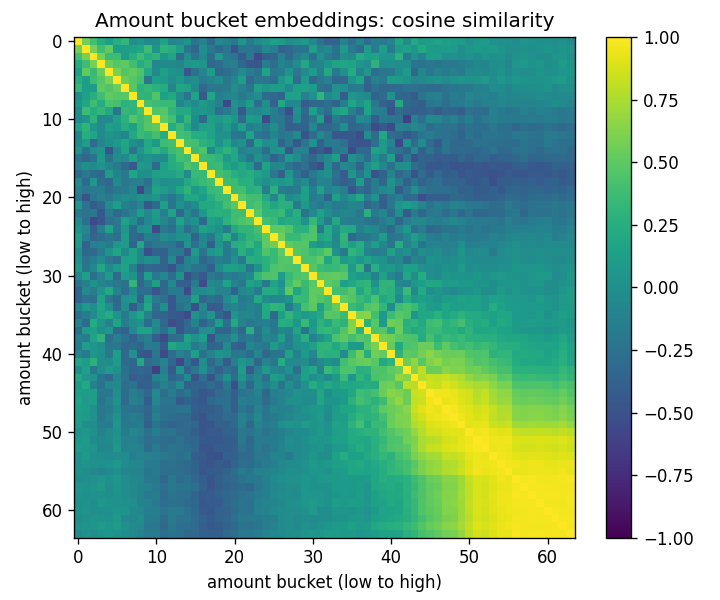

In [5]:
import pandas as pd
from IPython.display import Image, display


def summarize(ckpt_path):
    metrics = pd.read_csv(ckpt_path.parent / "metrics.csv")
    _, specs, _ = enc.load_encoder(ckpt_path, torch.device("cpu"))
    fields = [s.name for s in specs]
    summary = pd.DataFrame({
        "accuracy": [metrics[f"acc_{f}"].iloc[-1] for f in fields],
        "baseline": [metrics[f"baseline_{f}"].iloc[-1] for f in fields],
    }, index=fields)
    summary["lift"] = summary.accuracy - summary.baseline
    extra = [c for c in metrics.columns if c.startswith("acc1_") or c.endswith("_nonzero")]
    print(metrics[["epoch", "train_loss", "valid_loss", "seconds"]].to_string(index=False), "\n")
    print(summary.round(3).to_string(), "\n")
    print(metrics[["epoch"] + extra].round(3).to_string(index=False))
    display(Image(filename=str(ckpt_path.parent / "amount_embedding_cosine.png")))


summarize(main_ckpt)

## 5. Model size decision (record)

On 2026-11-20 the original 1.5M model (`small_seed42`: 2 layers, d_model 128) was compared with a 4.29M model (`capacity_check_seed42`: 4 layers, d_model 256), same data, seed and schedule. Rule fixed before the run: keep the larger model only if its validation masked loss is at least 5% lower. It was 17.4% lower (0.669 against 0.810), so all main and ablation runs use the larger model. This cell only reloads both saved runs and prints the comparison; it trains nothing.

In [6]:
def compare(ckpts):
    table = {}
    for ckpt in ckpts:
        model, specs, cfg = enc.load_encoder(ckpt, torch.device("cpu"))
        last = pd.read_csv(ckpt.parent / "metrics.csv").iloc[-1]
        table[ckpt.parent.name] = {
            "parameters": sum(p.numel() for p in model.parameters()),
            "valid_loss": last.valid_loss,
            "train_loss": last.train_loss,
            "minutes": last.seconds / 60,
            **{f"acc_{s.name}": last[f"acc_{s.name}"] for s in specs},
        }
    return pd.DataFrame(table)


size_runs = [OUT_DIR / name / "checkpoint.pt" for name in ("small_seed42", "capacity_check_seed42")]
if all(p.exists() for p in size_runs):
    comparison = compare(size_runs)
    print(comparison.round(4).to_string())
    gain = 1 - comparison.loc["valid_loss"].iloc[1] / comparison.loc["valid_loss"].iloc[0]
    print(f"\nValidation loss reduction from the larger model: {gain:.1%} (rule: keep it only if >= 5%)")
else:
    print("Size-check runs not found on Drive:", [str(p) for p in size_runs if not p.exists()])

                       small_seed42  capacity_check_seed42
parameters             1.475692e+06           4.291820e+06
valid_loss             8.101000e-01           6.693000e-01
train_loss             1.066500e+00           8.725000e-01
minutes                4.590000e+00           6.855000e+00
acc_payment_format     8.689000e-01           9.057000e-01
acc_currency           9.984000e-01           9.996000e-01
acc_counterparty_bank  8.108000e-01           8.515000e-01
acc_direction          9.837000e-01           9.921000e-01
acc_amount_bucket      7.299000e-01           7.910000e-01
acc_time_gap_bucket    2.441000e-01           2.594000e-01

Validation loss reduction from the larger model: 17.4% (rule: keep it only if >= 5%)


## 5b. Remaining checkpoints (Task 8)

Pretrains the other four checkpoints with the adopted model: main seeds 43 and 44, whole-transaction masking, and no Δt. About 7 minutes each, so about 30 minutes in total, and finished runs are skipped. This comes before the exports and fine-tuning below, which need these checkpoints. Run by the Portion 2 owner (see `HANDOFF.md`).

In [7]:
PRETRAIN_RUNS = ["main_seed43", "main_seed44", "abl_whole_mask_seed42", "abl_no_dt_seed42"]

for name in PRETRAIN_RUNS:
    ckpt = run_or_load(name)
    last = pd.read_csv(ckpt.parent / "metrics.csv").iloc[-1]
    print(f"{name}: valid masked loss {last.valid_loss:.4f}\n")

main_seed43: 4,291,820 parameters on cuda; 5,862 steps
  epoch 1 step 200/5,862  loss 3.4028  lr 2.01e-04  15s
  epoch 1 step 400/5,862  loss 2.5190  lr 4.01e-04  29s
  epoch 1 step 600/5,862  loss 2.1530  lr 6.01e-04  43s
  epoch 1 step 800/5,862  loss 1.7967  lr 8.01e-04  57s
  epoch 1 step 1,000/5,862  loss 1.5270  lr 1.00e-03  71s
  epoch 1 step 1,200/5,862  loss 1.3448  lr 9.96e-04  85s
  epoch 1 step 1,400/5,862  loss 1.2641  lr 9.83e-04  99s
  epoch 1 step 1,600/5,862  loss 1.1668  lr 9.63e-04  113s
  epoch 1 step 1,800/5,862  loss 1.1107  lr 9.35e-04  127s
  epoch 1: train 1.9146  valid 0.8529  payment_format 0.868/0.408  currency 0.999/0.371  counterparty_bank 0.793/0.026  direction 0.983/0.737  amount_bucket 0.746/0.058  time_gap_bucket 0.231/0.137
  epoch 2 step 2,000/5,862  loss 1.0468  lr 8.99e-04  144s
  epoch 2 step 2,200/5,862  loss 1.0501  lr 8.57e-04  158s
  epoch 2 step 2,400/5,862  loss 0.9379  lr 8.09e-04  172s
  epoch 2 step 2,600/5,862  loss 0.9579  lr 7.56e-04  

## 6. Export frozen embeddings (Task 5)

One embedding per transaction for Portion 3: the target-row vector (first 256 columns), then the mean over the window's real rows (last 256), so 512 float16 values. If fewer are wanted, the first 256 columns are the target-only version. Rows follow `window_index.csv.gz` order and cover all splits including tail; the `_ids.npy` file holds the `transaction_id` of each row, so join on that.

Each file is about 5.2 GB and takes about 5 to 10 minutes. It is written to the runtime's local disk first, then copied to Drive. Finished exports are skipped. The Portion 2 owner exports all five checkpoints after section 5b (see `HANDOFF.md`).

In [8]:
import numpy as np

EXPORT_RUNS = ["main_seed42", "main_seed43", "main_seed44", "abl_whole_mask_seed42", "abl_no_dt_seed42"]

for run in EXPORT_RUNS:
    target_dir = OUT_DIR / run
    emb_name, ids_name = f"embeddings_{run}.npy", f"embeddings_{run}_ids.npy"
    if (target_dir / emb_name).exists() and (target_dir / ids_name).exists():
        print("Already exported:", target_dir / emb_name)
    else:
        local_dir = Path("/content/exports") if Path("/content").exists() else OUT_DIR / "exports"
        emb_path, ids_path = enc.export_embeddings(target_dir / "checkpoint.pt", PROCESSED_DIR, local_dir, device=DEVICE)
        if local_dir != target_dir:
            for path in (emb_path, ids_path):
                shutil.copyfile(path, target_dir / path.name)  # copy2 also copies timestamps, which some mounts refuse
                print("Copied to", target_dir / path.name)
            emb_path.unlink()  # free the runtime's local disk before the next export
    embeddings = np.load(target_dir / emb_name, mmap_mode="r")
    ids = np.load(target_dir / ids_name)
    print(run, embeddings.shape, embeddings.dtype, f"{embeddings.nbytes / 1e9:.2f} GB")
    print("  ids:", len(ids), "unique:", len(np.unique(ids)))
    print("  finite in first 100K rows:", bool(np.isfinite(embeddings[:100_000]).all()))

Already exported: /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed42/embeddings_main_seed42.npy
main_seed42 (5078345, 512) float16 5.20 GB
  ids: 5078345 unique: 5078345
  finite in first 100K rows: True
  1,024,000/5,078,345 windows  34s
  2,048,000/5,078,345 windows  68s
  3,072,000/5,078,345 windows  101s
  4,096,000/5,078,345 windows  135s
Wrote embeddings_main_seed43.npy (5,078,345 x 512) in 168s
Copied to /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed43/embeddings_main_seed43.npy
Copied to /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed43/embeddings_main_seed43_ids.npy
main_seed43 (5078345, 512) float16 5.20 GB
  ids: 5078345 unique: 5078345
  finite in first 100K rows: True
  1,024,000/5,078,345 windows  34s
  2,048,000/5,078,345 windows  68s
  3,072,000/5,078,345 windows  102s
  4,096,000/5,078,345 windows  136s
Wrote embeddings_main_seed44.npy (5,078,345 x 512) in 169s
Copied to /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed44/embed

## 7. Fine-tuning (Task 6)

Adds a small MLP head on the target-row vector and trains encoder and head end to end on one labelled train subset only (unlabelled train transactions are not negatives). Class-weighted loss; each epoch uses every positive plus at most 200,000 negatives; at most 10 epochs, early stopping after 3 epochs without a gain in validation PR AUC. Writes `scores.csv` (`transaction_id, split, score` for valid and test, from the best epoch), `finetune_log.csv` and `summary.json` to `OUT_DIR/finetune/ft_<run>_<pct>pct_seed<seed>/`. Test is scored but never used for any choice.

`FT_RUNS` lists (pretraining run, label fraction, downstream seed). Downstream seed s uses the main checkpoint pretrained with seed s; ablations use their seed-42 checkpoint with seeds 42, 43 and 44. Finished runs are skipped.

In [ ]:
FT_RUNS = [
    ("main_seed42", 0.05, 42),  # Portion 2 owner: one reference run to prove the pipeline
]
# Portion 3, Experiments A and C (see HANDOFF.md): uncomment to run the grid. Finished runs are skipped.
# FT_RUNS = [(f"main_seed{s}", f, s) for f in (0.01, 0.05, 0.2, 1.0) for s in (42, 43, 44)]
# FT_RUNS += [(run, 0.05, s) for run in ("abl_whole_mask_seed42", "abl_no_dt_seed42") for s in (42, 43, 44)]

FT_DIR = OUT_DIR / "finetune"
for run, fraction, seed in FT_RUNS:
    done = FT_DIR / f"ft_{run}_{fraction * 100:g}pct_seed{seed}" / "scores.csv"
    if done.exists():
        print("Already done:", done)
        continue
    enc.finetune(OUT_DIR / run / "checkpoint.pt", PROCESSED_DIR, FT_DIR, fraction=fraction, seed=seed, device=DEVICE)

summaries = [json.loads(p.read_text()) for p in sorted(FT_DIR.glob("ft_*/summary.json"))]
print(pd.DataFrame(summaries).to_string(index=False))

Fine-tuning main_seed42 on 5% labels, seed 42: 127 positives, 162,320 negatives
  epoch 1: train loss 2.4577  valid PR AUC 0.4168  45s
  epoch 2: train loss 1.5241  valid PR AUC 0.2861  89s
  epoch 3: train loss 1.4931  valid PR AUC 0.3678  134s
  epoch 4: train loss 1.5036  valid PR AUC 0.4280  178s
  epoch 5: train loss 1.2821  valid PR AUC 0.2850  223s
  epoch 6: train loss 1.0911  valid PR AUC 0.3938  267s
  epoch 7: train loss 0.8041  valid PR AUC 0.3766  312s
  early stop: no gain for 3 epochs
Best epoch 4: valid PR AUC 0.4280. Wrote /content/drive/MyDrive/TabBERT_AML/portion2_runs/finetune/ft_main_seed42_5pct_seed42/scores.csv
        run  fraction  seed  best_epoch  valid_ap  positives  negatives
main_seed42      0.05    42           4  0.427957        127     162320


## 8. Reconstruction score (Task 7)

Zero-shot anomaly score for Portion 4. For each valid, test and tail transaction, the encoder sees the window five times, each time with one field of the target transaction masked (payment format, currency, counterparty bank, amount, time gap; direction is skipped), and records how surprised it is by the true value (negative log likelihood). Output `recon_<run>.csv`: `transaction_id, split`, one `nll_<field>` column per field and `nll_sum`. Portion 4 normalises per field. About 1.83M transactions; written locally, then copied to Drive.

The check at the end compares laundering and normal transactions on validation only: a higher mean score and a PR AUC above the positive rate mean the score carries some signal before any labels are used.

In [ ]:
from sklearn.metrics import average_precision_score

RECON_RUNS = ["main_seed42"]
# Portion 4, for seed variation: add "main_seed43", "main_seed44" (each about 5 minutes)

for run in RECON_RUNS:
    target = OUT_DIR / run / f"recon_{run}.csv"
    if target.exists():
        print("Already done:", target)
    else:
        local_dir = Path("/content/recon") if Path("/content").exists() else OUT_DIR / "recon"
        path = enc.reconstruction_scores(OUT_DIR / run / "checkpoint.pt", PROCESSED_DIR, local_dir, device=DEVICE)
        if path != target:
            shutil.copyfile(path, target)
            print("Copied to", target)

    recon = pd.read_csv(target)
    labels = pd.read_csv(PROCESSED_DIR / "window_index.csv.gz", usecols=["transaction_id", "is_laundering"])
    valid = recon[recon.split == "valid"].merge(labels, on="transaction_id")
    nll_cols = [c for c in recon.columns if c.startswith("nll_")]
    print(recon.groupby("split").size().to_string(), "\n")
    print("Mean score on valid, by label:")
    print(valid.groupby("is_laundering")[nll_cols].mean().round(3).to_string(), "\n")
    print(f"Valid PR AUC of nll_sum: {average_precision_score(valid.is_laundering, valid.nll_sum):.4f} "
          f"(positive rate {valid.is_laundering.mean():.4f})")

  512,000/1,829,424 windows  67s
  1,024,000/1,829,424 windows  134s
  1,536,000/1,829,424 windows  200s
Wrote recon_main_seed42.csv (1,829,424 rows) in 254s
Copied to /content/drive/MyDrive/TabBERT_AML/portion2_runs/main_seed42/recon_main_seed42.csv
split
tail       1108
test     862792
valid    965524 

Mean score on valid, by label:
               nll_payment_format  nll_currency  nll_counterparty_bank  nll_amount_bucket  nll_time_gap_bucket  nll_sum
is_laundering                                                                                                          
0                           0.174         0.001                  0.889              0.518                2.262    3.844
1                           1.150         0.062                  5.335              2.079                1.561   10.188 

Valid PR AUC of nll_sum: 0.0113 (positive rate 0.0011)
